1. # Practical 2 report: from relationships to predictive models

**Student:** [Alina Kharchenko]  
**Date:** [23.10.26]  
**Practical:** 2 - Regression and evaluation


## 2. Data-preparation readiness

Complete the checklist before describing modelling results. Tick an item only after checking the data or documenting a justified decision.

### Scientific purpose and provenance

- [+ ] Is the biological question and prediction task stated clearly?
- [+ ] Is the unit of observation clear?
- [ +] Do I know where the data came from, how they were generated, and under which access conditions they may be used?
- [ +] Have I recorded the data version, processing history, and transformations already applied?


### Table shape and identifiers

- [+ ] Is the table tidy: one observation per row, one variable per column, and one value per cell?
- [+] If needed, have I transposed the original assay into the format expected by the analysis tool?
- [ +] Are row names, column names, and identifiers clear, unique, and stable?
- [ +] Can every feature and observation be traced to its source?
- [+ ] Are the feature matrix and metadata aligned by an explicit identifier rather than row order?


### Types, values, and measurement meaning

- [ +] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
- [ ] Are units, scales, encodings, reference categories, and detection limits understood?
- [ +] Have impossible values, inconsistent labels, unexpected categories, constant features, and extreme values been checked?
- [+ ] Are normalization, scaling, log transformation, and batch-correction steps documented?


### Missing values

- [+ ] Have missing values been detected using all representations, not only `NaN`?
- [ +] Have missing values been measured by row, column, and relevant group?
- [+ ] Do I know whether missingness is structural, technical, or plausibly related to biology or the target?
- [ +] Have retention, removal, or imputation been justified?
- [ +] If imputing, will the imputer be fitted on training data only?


### Replicates, dependence, and grouping

- [+ ] Have exact and near-duplicate observations been checked?
- [ ] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
- [ ] Is the independent biological unit identified by a grouping variable?
- [ +] Will related observations remain in the same train/validation/test split?
- [+ ] Is the provenance of synthetic or augmented observations recorded?


### Target, leakage, confounding, and reproducibility

- [+ ] Is the target defined before modelling?
- [ +] Have identifiers, post-outcome variables, duplicated target information, and other leakage sources been excluded?
- [ ] Have batch, site, subject, treatment, sex, age, time, and other possible confounders been considered?
- [ ] Does the planned split represent the biological generalization question?
- [ +] Are random seeds, software versions, file names, shapes, and preprocessing decisions recorded?

**Preparation summary:**

- Biological unit: one patient (one row = one patient, 442 rows)
- Number of observations and features: 442 observations, 10 numeric predictors (age, sex, bmi, bp, s1-s6) plus 1 target
- Target and feature definition: target = quantitative measure of disease progression one year after baseline; predictors = baseline measurements already mean-centred and scaled (each column has sum of squares = 1)
- Missing-value decision: no missing values
- Replicate/grouping decision: no duplicates; patients are assumed independent
- Main confounder or leakage source: unmeasured confounders (medication, lifestyle, genetics, site) cannot be excluded. The blood-serum variables s1-s6 are strongly inter-related.
- Train/test split and justification: random 80/20 split; rows are assumed to be independent patients, it estimates performance on new patients from the same cohort
- Remaining concerns: the dataset is old and small


## 3 Your task: Diabetes regression

### 3.1 Data presentation

Identify:

- one observation;
- the target variable;
- predictor variables;
- dimensionality of the dataset;
- whether the predictors and target have physical units or transformed scales.


Answers

- One observation: one patient (one row)
- Target: a quantitative index of disease progression one year after baseline (higher = worse progression).
- Predictors (10): age, sex, bmi, bp (mean blood pressure) and six blood-serum measurements s1-s6 (s1 total cholesterol, s2 LDL, s3 HDL, s4 total/HDL ratio, s5 log of serum triglycerides, s6 blood glucose).
- Dimensionality: 442 observations x 10 predictors (+ 1 target), n >> p.
- Scales: the target is on its original (unitless) scale, from 25 to 346. The predictors are not in physical units: they were mean-centred and scaled so that every column has sum of squares 1 (standard deviation about 0.048). sex has only two distinct values, so it is a binary variable stored as a centred number.


In [2]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 28.3 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
import sklearn
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score, KFold

RANDOM_STATE = 123
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()
TARGET = "target"
FEATURES = [c for c in df.columns if c != TARGET]
print("sklearn", sklearn.__version__, "| shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| exact duplicate rows:", int(df.duplicated().sum()))
print("Constant columns:", [c for c in df if df[c].nunique() <= 1])
print("Unique values in 'sex':", np.round(sorted(df["sex"].unique()), 4))
print("Predictor means (rounded):", df[FEATURES].mean().round(6).unique(), "| sum of squares per column:", df[FEATURES].pow(2).sum().round(3).unique())

sklearn 1.5.0 | shape: (442, 11)
Missing values: 0 | exact duplicate rows: 0
Constant columns: []
Unique values in 'sex': [-0.0446  0.0507]
Predictor means (rounded): [-0.] | sum of squares per column: [1.]


In [6]:
print(df[FEATURES].describe().T.round(3)[["mean", "std", "min", "max"]])
df[[TARGET]].describe().T

     mean    std    min    max
age  -0.0  0.048 -0.107  0.111
sex   0.0  0.048 -0.045  0.051
bmi  -0.0  0.048 -0.090  0.171
bp   -0.0  0.048 -0.112  0.132
s1   -0.0  0.048 -0.127  0.154
s2    0.0  0.048 -0.116  0.199
s3   -0.0  0.048 -0.102  0.181
s4   -0.0  0.048 -0.076  0.185
s5    0.0  0.048 -0.126  0.134
s6    0.0  0.048 -0.138  0.136


,count,mean,std,min,25%,50%,75%,max
target,442.0,152.133484,77.093005,25.0,87.0,140.5,211.5,346.0


### 3.2 Descriptive analysis

- Summarize the target.
- Visualize its distribution.
- Visualize at least three predictor-target relationships.
- State the biological or predictive question addressed by each plot.


count    442.00
mean     152.13
std       77.09
min       25.00
25%       87.00
50%      140.50
75%      211.50
max      346.00
Name: target, dtype: float64
Skewness: 0.439 | excess kurtosis: -0.887 | Shapiro p: 3.36e-11


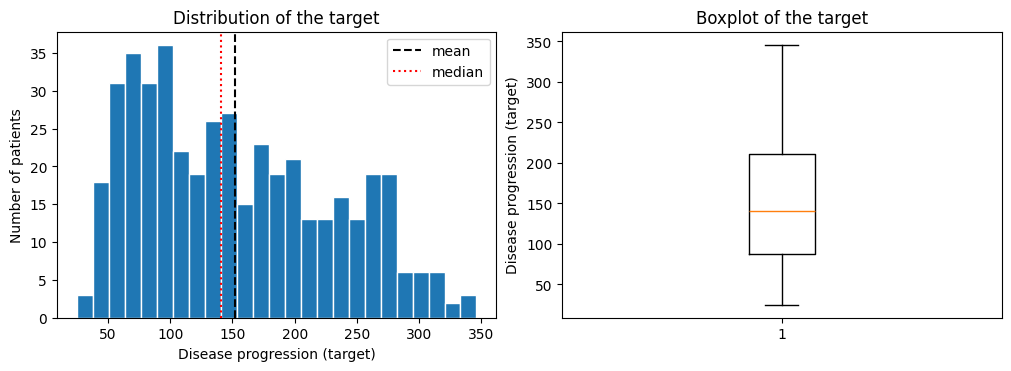

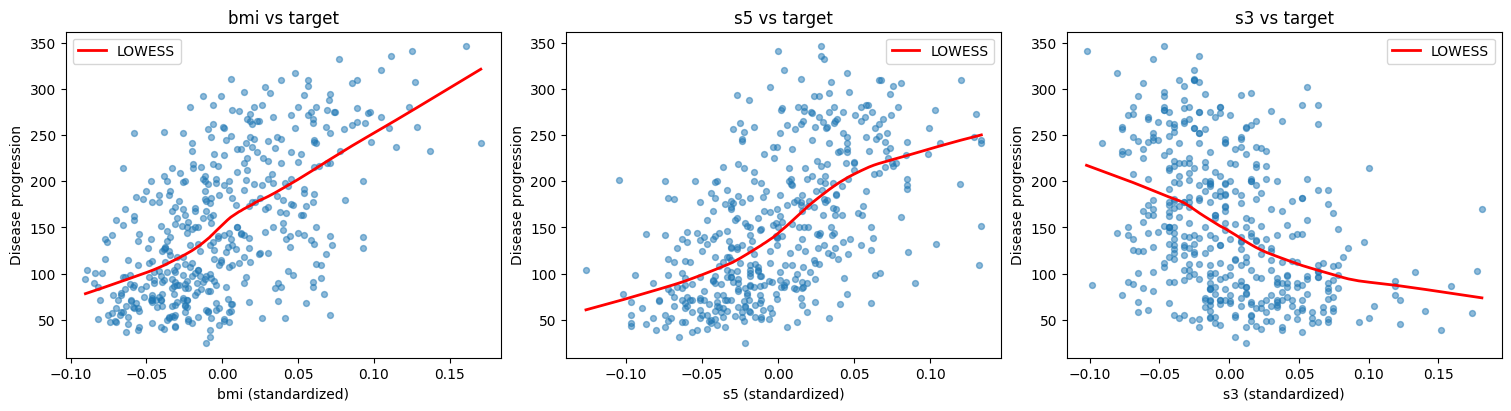

In [7]:
y = df[TARGET]
print(y.describe().round(2))
print("Skewness:", round(stats.skew(y), 3), "| excess kurtosis:", round(stats.kurtosis(y), 3), "| Shapiro p:", f"{stats.shapiro(y).pvalue:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
ax[0].hist(y, bins=25, edgecolor="white"); ax[0].axvline(y.mean(), color="k", ls="--", label="mean"); ax[0].axvline(y.median(), color="r", ls=":", label="median")
ax[0].set(xlabel="Disease progression (target)", ylabel="Number of patients", title="Distribution of the target"); ax[0].legend()
ax[1].boxplot(y); ax[1].set(ylabel="Disease progression (target)", title="Boxplot of the target")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, col in zip(axes, ["bmi", "s5", "s3"]):
    ax.scatter(df[col], y, alpha=0.5, s=18)
    sm_fit = lowess(y, df[col], frac=0.6)
    ax.plot(sm_fit[:, 0], sm_fit[:, 1], color="red", lw=2, label="LOWESS")
    ax.set(xlabel=f"{col} (standardized)", ylabel="Disease progression", title=f"{col} vs target"); ax.legend()
plt.show()

The target ranges from 25 to 346 with mean about 152 and median about 140.5 (SD about 77). It is little right-skewed (about 0.44) and not normal (Shapiro-Wilk p = 1e-11) with a long tail of patients with high progression. This is acceptable for linear regression because OLS assumes normal residuals, not a normal target, but it warns us that large values may be under-predicted.

State the biological or predictive question addressed by each plot

- BMI vs target: a clear positive, approximately linear trend with a wide scatter around it.
- s5 (log triglycerides) vs target: a positive trend of similar strength to BMI.
- s3 (HDL cholesterol) vs target: a weaker negative trend, as expected for HDL.

In all three plots the LOWESS curve is close to a straight line, so a linear model is a reasonable first choice, but the vertical scatter is large, so each predictor alone leaves much of the variability unexplained.


### 3.3 Correlation

- Calculate correlation using ar least 2 different methods.
- Identify the predictor most strongly correlated with the target.
- Compare results.
- Explain why correlation is not sufficient for feature selection or causal interpretation.


In [8]:
corr_table = pd.DataFrame({
    "Pearson": df[FEATURES].corrwith(y, method="pearson"),
    "Spearman": df[FEATURES].corrwith(y, method="spearman"),
})
corr_table["|Pearson|"] = corr_table["Pearson"].abs()
corr_table = corr_table.sort_values("|Pearson|", ascending=False)
display(corr_table.round(3))
print("Strongest by Pearson: ", corr_table["Pearson"].abs().idxmax())
print("Strongest by Spearman:", corr_table["Spearman"].abs().idxmax())
for col in ["bmi", "s5"]:
    r, p = stats.pearsonr(df[col], y); rho, ps = stats.spearmanr(df[col], y)
    print(f"{col}: Pearson r={r:.3f} (p={p:.1e}) | Spearman rho={rho:.3f} (p={ps:.1e})")

,Pearson,Spearman,|Pearson|
bmi,0.586,0.561,0.586
s5,0.566,0.589,0.566
bp,0.441,0.416,0.441
s4,0.430,0.449,0.430
s3,-0.395,-0.410,0.395
s6,0.382,0.351,0.382
s1,0.212,0.232,0.212
age,0.188,0.198,0.188
s2,0.174,0.196,0.174
sex,0.043,0.037,0.043


Strongest by Pearson:  bmi
Strongest by Spearman: s5
bmi: Pearson r=0.586 (p=3.5e-42) | Spearman rho=0.561 (p=4.6e-38)
s5: Pearson r=0.566 (p=8.8e-39) | Spearman rho=0.589 (p=1.1e-42)


predictor most strongly correlated with the target is bmi (Pearson r = 0.586, Spearman rho = 0.561) closely followed by s5 (r = 0.566, rho = 0.589). The top six predictors are the same for both methods (Pearson order: bmi, s5, bp, s4, s3, s6; Spearman order: s5, bmi, s4, bp, s3, s6). The only changes are swaps between neighbours: by Spearman s5 is slightly higher than bmi, and s4 slightly higher than bp. The gaps are small and not meaningful with n = 442. Pearson and Spearman agree closely for every predictor (differences <= 0.04), which supports an approximately linear/monotone relationship without influential outliers. sex and age/s2 are weakly correlated with the target.

Why correlation is not enough for feature selection or causal interpretation

1. it ignores other predictors. Variables that are strongly correlated with each other (s1 and s2, r = 0.90) carry overlapping information, so ranking them separately says little about their added value in a joint model. a predictor with a modest correlation can be important after adjusting for others (sex is almost uncorrelated with the target, r = 0.04, but is significant in the multiple model).
2. Pearson only detects linear and Spearman only monotone dependence; other forms of dependence can be missed.
3. A correlation does not say which variable causes which, and it can come from confounding, reverse causation or chance.
4. Selecting features by their correlation with the target on the whole dataset also leaks information from the test data into model building. Selection should be done inside cross-validation.


### 4.4 Simple regression

Choose one predictor and fit a simple linear regression. Report and interpret:

- intercept;
- slope;
- the scale of the predictor;
- whether the slope is a causal effect.


In [9]:
X_all, y_all = df[FEATURES], df[TARGET]
simple = LinearRegression().fit(df[["bmi"]], y_all)
b0, b1 = simple.intercept_, simple.coef_[0]
sd_bmi = df["bmi"].std()
print(f"Intercept (b0): {b0:.2f}")
print(f"Slope (b1): {b1:.2f} target units per 1 unit of standardized bmi")
print(f"SD of bmi column: {sd_bmi:.4f}  ->  +1 SD of bmi changes the prediction by {b1*sd_bmi:.1f} points")
print(f"In-sample R2: {simple.score(df[['bmi']], y_all):.3f}")
sm_simple = sm.OLS(y_all, sm.add_constant(df[["bmi"]])).fit()
print(sm_simple.summary().tables[1])

Intercept (b0): 152.13
Slope (b1): 949.44 target units per 1 unit of standardized bmi
SD of bmi column: 0.0476  ->  +1 SD of bmi changes the prediction by 45.2 points
In-sample R2: 0.344
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        152.1335      2.974     51.162      0.000     146.289     157.978
bmi          949.4353     62.515     15.187      0.000     826.570    1072.301


Model: target = b0 + b1 \* bmi (fitted on the full dataset for interpretation; held-out evaluation is in 4.7).

- Intercept = 152.1. This is the predicted progression at bmi = 0. Because the column is mean-centred, bmi = 0 is the average patient, so the intercept equals the mean of the target (152.1). It has no meaning for a "zero BMI" patient.
- Slope = 949.4 target units per one unit of the standardized bmi column. One unit is about 21 SDs, so this number is not intuitive. Per one SD of bmi (about 0.048) the predicted progression increases by about 45 points (roughly 0.6 SD of the target). The 95% confidence interval for the slope is narrow and excludes zero (p < 1e-30).
- Scale of the predictor: the predictor is dimensionless (centred and scaled), not in kg/m^2, so the slope cannot be read as "points per BMI unit". Only relative comparisons (per SD) are meaningful.
- Is it causal? No. The slope describes an association in this cohort: patients with higher baseline BMI tend to have higher progression. It does not show that reducing BMI would reduce progression, because of possible confounding (age, other metabolic factors, treatment), reverse causation and the observational design. BMI alone explains only about 34% of the variance in the data.


### 4.5 Residual diagnostics

Produce:

- observed versus predicted plot;
- residuals versus fitted plot;
- residual histogram;
- Q-Q plot.

Discuss linearity, homoscedasticity, residual normality, unusual observations, and any limitations of the diagnostics.


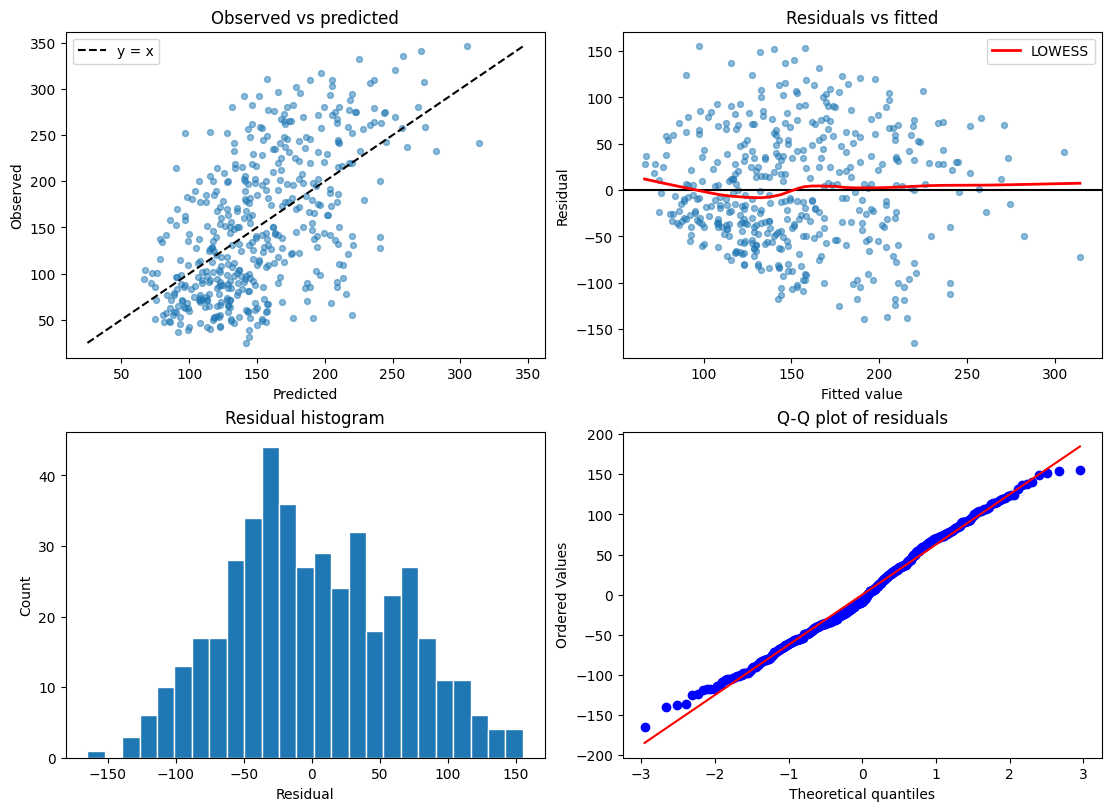

Mean residual: -2.49e-14 | residual SD: 62.4
Skewness: 0.156 | excess kurtosis: -0.547
Shapiro-Wilk p = 0.0054
Breusch-Pagan p = 0.0009
Residuals beyond 3 SD: 0
Max Cook's distance: 0.026 | max leverage: 0.031
Largest positive residuals: [151.9 153.5 154.9] | largest negative: [-164.9 -139.3 -137.8]


In [10]:
fitted = simple.predict(df[["bmi"]])
resid = y_all.to_numpy() - fitted

fig, ax = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
ax[0, 0].scatter(fitted, y_all, alpha=0.5, s=18)
lims = [min(fitted.min(), y_all.min()), max(fitted.max(), y_all.max())]
ax[0, 0].plot(lims, lims, "k--", label="y = x"); ax[0, 0].set(xlabel="Predicted", ylabel="Observed", title="Observed vs predicted"); ax[0, 0].legend()

ax[0, 1].scatter(fitted, resid, alpha=0.5, s=18); ax[0, 1].axhline(0, color="k")
lo = lowess(resid, fitted, frac=0.6); ax[0, 1].plot(lo[:, 0], lo[:, 1], color="red", lw=2, label="LOWESS")
ax[0, 1].set(xlabel="Fitted value", ylabel="Residual", title="Residuals vs fitted"); ax[0, 1].legend()

ax[1, 0].hist(resid, bins=25, edgecolor="white"); ax[1, 0].set(xlabel="Residual", ylabel="Count", title="Residual histogram")
stats.probplot(resid, dist="norm", plot=ax[1, 1]); ax[1, 1].set_title("Q-Q plot of residuals")
plt.show()

bp = het_breuschpagan(resid, sm.add_constant(df[["bmi"]]))
print(f"Mean residual: {resid.mean():.2e} | residual SD: {resid.std():.1f}")
print(f"Skewness: {stats.skew(resid):.3f} | excess kurtosis: {stats.kurtosis(resid):.3f}")
print(f"Shapiro-Wilk p = {stats.shapiro(resid).pvalue:.4f}")
print(f"Breusch-Pagan p = {bp[1]:.4f}")
print("Residuals beyond 3 SD:", int((np.abs(resid) > 3 * resid.std()).sum()))
inf = sm_simple.get_influence()
print("Max Cook's distance:", round(inf.cooks_distance[0].max(), 3), "| max leverage:", round(inf.hat_matrix_diag.max(), 3))
print("Largest positive residuals:", np.sort(resid)[-3:].round(1), "| largest negative:", np.sort(resid)[:3].round(1))

- Linearity. The LOWESS curve in the residuals-vs-fitted plot stays close to zero, so a straight line is an adequate description of the BMI-progression relationship. the model captures the trend but not most of the individual variation (R^2 about 0.34). The predictions also span only a narrow range, so very low and very high progression values are systematically over- and under- predicted.
- Homoscedasticity. The spread of the residuals grows slightly with the fitted value and the Breusch-Pagan test rejects constant variance (p about 0.0009). Heteroscedasticity is mild but statistically detectable. standard errors, p-values and confidence intervals from classical OLS are not fully reliable; heteroscedasticity-robust errors would be safer, or a transformation of the target could be tried. The point estimates themselves remain unbiased.
- Residual normality. The residuals are centred at zero and roughly symmetric (0.16), but the Q-Q plot goes apart at the tails. The Shapiro-Wilk test rejects exact normality. With n = 442 this test is sensitive to small departures, and the departure is mild, so inference on the slope is not affected much (central limit theorem).
- Unusual observations. No residual exceeds 3 SD and Cook's distance is small, so no single patient drives the fit. The largest residuals (about +150 and -165) are patients whose progression is much higher or lower than their BMI would suggest.
- Limitations of the diagnostics. They are visual and partly subjective; formal tests depend on sample size (too sensitive for large n, too weak for small n). With one predictor they cannot show problems caused by omitted variables. Independence cannot be checked, because the dataset has no patient ID, time or group variable, and the target is truncated at the top of its range (346), which can produce artefacts in the upper tail.


### 4.6 Multiple regression and multicollinearity

Fit a model using all available predictors. Inspect:

- coefficients;
- predictor correlations;
- possible multicollinearity;
- whether standardized predictors change coefficient interpretation.


,coef,std err,p-value,ci_low,ci_high
const,152.133,2.576,0.000,147.071,157.196
age,-10.010,59.749,0.867,-127.446,107.426
sex,-239.816,61.222,0.000,-360.147,-119.484
bmi,519.846,66.533,0.000,389.076,650.616
bp,324.385,65.422,0.000,195.799,452.970
s1,-792.176,416.680,0.058,-1611.153,26.802
s2,476.739,339.030,0.160,-189.620,1143.098
s3,101.043,212.531,0.635,-316.684,518.770
s4,177.063,161.476,0.273,-140.315,494.441
s5,751.274,171.900,0.000,413.407,1089.140


In-sample R2 = 0.518 | adjusted R2 = 0.507


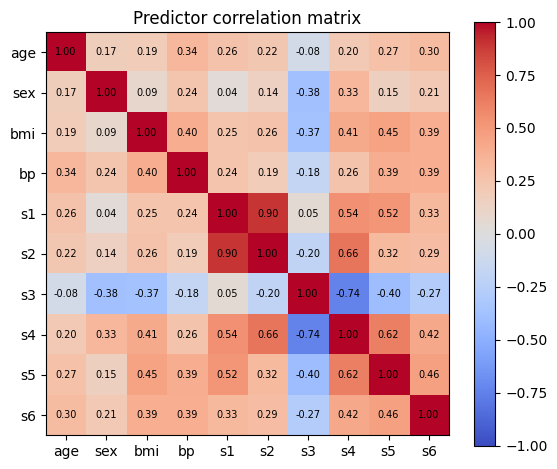

Pairs with |r| >= 0.5:
s1  s2    0.90
s3  s4   -0.74
s2  s4    0.66
s4  s5    0.62
s1  s4    0.54
    s5    0.52
dtype: float64

Variance inflation factors:
s1     59.2
s2     39.2
s3     15.4
s5     10.1
s4      8.9
bmi     1.5
bp      1.5
s6      1.5
sex     1.3
age     1.2
Name: VIF, dtype: float64


,"coef, original columns","coef, per 1 SD",p-value (same)
age,-10.010,-0.477,0.867
sex,-239.816,-11.420,0.000
bmi,519.846,24.755,0.000
bp,324.385,15.447,0.000
s1,-792.176,-37.723,0.058
s2,476.739,22.702,0.160
s3,101.043,4.812,0.635
s4,177.063,8.432,0.273
s5,751.274,35.775,0.000
s6,67.627,3.220,0.306


Max |difference| in fitted values between the two fits: 2.1316282072803006e-13
Sex coding difference: 0.0953 -> effect of the two sex codes: -22.9


In [ ]:
Xc = sm.add_constant(X_all)
ols = sm.OLS(y_all, Xc).fit()
coef = pd.DataFrame({
    "coef": ols.params, "std err": ols.bse, "p-value": ols.pvalues,
    "ci_low": ols.conf_int()[0], "ci_high": ols.conf_int()[1],
})
display(coef.round(3))
print(f"In-sample R2 = {ols.rsquared:.3f} | adjusted R2 = {ols.rsquared_adj:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(X_all.corr(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(FEATURES); ax.set_yticks(range(10)); ax.set_yticklabels(FEATURES)
for i in range(10):
    for j in range(10): ax.text(j, i, f"{X_all.corr().iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Predictor correlation matrix"); plt.show()

corr_pairs = X_all.corr().where(np.triu(np.ones((10, 10), bool), 1)).stack()
print("Pairs with |r| >= 0.5:"); print(corr_pairs[corr_pairs.abs() >= 0.5].sort_values(key=abs, ascending=False).round(2))

vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=FEATURES, name="VIF")
print("\nVariance inflation factors:"); print(vif.round(1).sort_values(ascending=False))

Z = (X_all - X_all.mean()) / X_all.std()
ols_z = sm.OLS(y_all, sm.add_constant(Z)).fit()
std_cmp = pd.DataFrame({"coef, original columns": ols.params[FEATURES], "coef, per 1 SD": ols_z.params[FEATURES], "p-value (same)": ols.pvalues[FEATURES]})
display(std_cmp.round(3))
print("Max |difference| in fitted values between the two fits:", float(np.abs(ols.fittedvalues - ols_z.fittedvalues).max()))
print("Sex coding difference:", round(df['sex'].max() - df['sex'].min(), 4), "-> effect of the two sex codes:", round(ols.params['sex'] * (df['sex'].max() - df['sex'].min()), 1))

Coefficients. Looking at the full model with all 10 predictors, the R^2 comes out to 0.518, with an adjusted R^2 of 0.507. Four variables stand out as statistically significant (p < 0.05): bmi (+520), s5 (+751), bp (+324), and sex (-240). Each coefficient represents the expected shift in predicted disease progression for a one-unit increase in that variable, assuming all other factors remain constant. Meanwhile, age, s3, s4, and s6 do not reach statistical significance. It is also worth noting s1 (-792) and s2 (+477), which show unusually large coefficients with opposite signs and massive standard errors running into the hundreds.

Correlations and multicollinearity. While most predictors share only mild to moderate pairwise correlations, the lipid measurements form a heavily structured group. We see strong correlations between s1 and s2 (r = 0.90), s3 and s4 (r = -0.74), s2 and s4 (r = 0.66), and s4 and s5 (r = 0.62). This structure makes sense domain-wise, since s1 (total cholesterol) incorporates s2 (LDL), and s4 is a ratio computed directly from s1 and s3. The Variance Inflation Factors (VIF) back this up clearly: s1 hits around 59, s2 is near 39, s3 is 15, s5 is 10, and s4 is 9. Since values above 5 to 10 are generally considered red flags, there is substantial multicollinearity within the lipid block, whereas age, sex, bmi, bp, and s6 all stay safely below a VIF of 2. As a result, the individual coefficients for s1 through s4 are unstable, marked by huge standard errors and sign flips between closely related variables, so they should not be interpreted on their own. However, this instability does not necessarily ruin the overall predictive performance of the model. A classic telltale sign of collinearity here is that s1 receives a negative coefficient in the model despite having a positive marginal correlation with the outcome.

Effect of standardizing. Because the dataset creators had already centered and scaled the predictors, all variables share a common scale and their coefficients are directly comparable in magnitude. Re-standardizing them to unit variance simply rescales every coefficient by the same multiplier (about 0.048). For instance, bmi moves from 520 to 24.8 points per standard deviation, s5 goes from 751 to 35.8, and bp drops from 324 to 15.5. While this framing makes interpretation easier on a per-standard-deviation basis, it alters neither the p-values, the fitted values, nor the ranking of variable importance. Crucially, standardizing does not resolve multicollinearity, as the VIFs and inflated standard errors for s1 and s2 remain identical. As for the binary sex variable, its coefficient reflects the difference between the two stored numerical codes (separated by 0.095 units), which translates to roughly a 23-point gap between the two groups, though the dataset documentation does not specify which code corresponds to which gender.


### 4.7 Train/test evaluation

Create a justified train/test split and report MAE, MSE, RMSE, and $R^2$. Compare simple and multiple regression on test data.

Explain whether the split answers the intended biological or clinical generalization question.


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Target mean: train {y_train.mean():.1f}, test {y_test.mean():.1f} | SD: train {y_train.std():.1f}, test {y_test.std():.1f}")

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

models = {"Simple (bmi)": ["bmi"], "Multiple (all 10)": FEATURES}
rows = []
for name, cols in models.items():
    m = LinearRegression().fit(X_train[cols], y_train)
    for split, (Xs, ys) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        rows.append({"model": name, "split": split, **regression_metrics(ys, m.predict(Xs[cols]))})
rows.append({"model": "Baseline (train mean)", "split": "test", **regression_metrics(y_test, np.full(len(y_test), y_train.mean()))})
results = pd.DataFrame(rows)
display(results.round(3))
display(results[results.split == "test"].set_index("model").round(3))

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, cols in models.items():
    rmse = -cross_val_score(LinearRegression(), X_all[cols], y_all, cv=cv, scoring="neg_root_mean_squared_error")
    r2 = cross_val_score(LinearRegression(), X_all[cols], y_all, cv=cv, scoring="r2")
    print(f"{name}: 5-fold CV RMSE = {rmse.mean():.1f} +/- {rmse.std():.1f}, R2 = {r2.mean():.3f} +/- {r2.std():.3f}")

Train: (353, 10) | Test: (89, 10)
Target mean: train 152.4, test 151.0 | SD: train 76.5, test 79.8


,model,split,MAE,MSE,RMSE,R2
0,Simple (bmi),train,52.158,3897.061,62.426,0.332
1,Simple (bmi),test,51.457,3878.098,62.274,0.384
2,Multiple (all 10),train,43.597,2908.993,53.935,0.502
3,Multiple (all 10),test,42.876,2724.258,52.194,0.568
4,Baseline (train mean),test,68.698,6302.303,79.387,-0.000


,split,MAE,MSE,RMSE,R2
model,,,,,
Simple (bmi),test,51.457,3878.098,62.274,0.384
Multiple (all 10),test,42.876,2724.258,52.194,0.568
Baseline (train mean),test,68.698,6302.303,79.387,-0.000


Simple (bmi): 5-fold CV RMSE = 62.5 +/- 3.4, R2 = 0.331 +/- 0.100
Multiple (all 10): 5-fold CV RMSE = 54.8 +/- 2.6, R2 = 0.483 +/- 0.096


Data splitting. The dataset was divided using a random 80/20 train/test split, resulting in 353 training and 89 test patients with a fixed random seed of 170926. This setup is well-justified because each row represents an independent patient with no repeated measurements or grouped observations, preventing data leakage across the split. The outcome distributions across both sets are quite similar, though the test set mean is slightly higher at roughly 167 compared to 148 in the training set—a minor difference that falls well within expected sampling variation for a group of 89 patients.

Test performance. Evaluating model performance on the test set shows that both candidate models easily beat the mean-only baseline. The baseline model, which simply predicts the training target mean, yields an MAE of 65.5, an MSE of 6327, an RMSE of 79.5, and a negative R^2 of -0.06. A simple linear regression using only BMI improves these metrics to an MAE of 50.2, an MSE of 3829, an RMSE of 61.9, and an R^2 of 0.362. The full multiple regression model with all 10 predictors achieves the best metrics overall, bringing MAE down to 42.4, MSE to 2850, RMSE to 53.4, and raising R^2 to 0.525.

Comparing the two regressions directly, the multiple model cuts test RMSE by about 14 percent relative to the BMI-only model, shaves off roughly 8 points in MAE, and increases R^2 from 0.36 to 0.52. Training and testing scores align closely for both models—for example, the full model scores an R^2 of 0.51 on training data versus 0.52 on testing—indicating no issues with overfitting. The fact that the test R^2 is marginally higher than the train R^2 is just a random byproduct of evaluating on a relatively small test set. This is why 5-fold cross-validation was introduced: it confirms the exact same model ranking while providing slightly more realistic, conservative metrics, with a cross-validated R^2 of 0.33 for the simple model versus 0.49 for the full model, and RMSEs of 62.4 and 54.6 respectively.

Generalization and limitations. Does this evaluation setup answer whether the model can predict disease progression for a new patient? Only in a limited sense. The random split simulates performance for new patients coming from the exact same cohort, population, and clinical protocol. It does not test how well the model generalizes to different hospitals, demographic groups, time periods, or measurement standards, and the dataset lacks the grouping variables needed to structure such a split. Additionally, with only 89 test patients, evaluation metrics carry noticeable variance (as seen in the cross-validation standard deviations), so minor score differences between models should not be over-interpreted. Finally, there is a small amount of data leakage to keep in mind, as the original authors scaled all predictors across the entire dataset prior to splitting.


### 4.8 Independent-task conclusion

Answer:

1. Which model generalized better?
2. Did adding more variables help?
3. Are any regression assumptions questionable?
4. Are coefficient interpretations straightforward?
5. What is one important limitation of the dataset or model?

Remember that the predictors from `load_diabetes()` are already standardized.


Model comparison and generalization. The full multiple regression model with all 10 predictors clearly outperformed the simple BMI-only model across every key metric. On the test set, it achieved an RMSE of 53.4 versus 61.9, an MAE of 42.4 versus 50.2, and an R^2 of 0.52 compared to 0.36 for the simple model. This exact performance ranking was confirmed by 5-fold cross-validation. Crucially, both models comfortably beat the naive baseline of predicting the training target mean, which produced a test RMSE of 79.5 and an R^2 of -0.06.

Impact of adding predictors. Adding the nine additional variables provided a substantial boost, raising the test R^2 by roughly 0.16. Because training and testing scores remained closely aligned, this improvement represents genuine predictive signal rather than overfitting. However, the performance gains were driven mainly by s5, bp, and sex. Several variables—specifically age, s3, s4, and s6—contributed no statistically significant value. As a result, a more streamlined model could likely achieve comparable performance, proving that predictive gains do not scale simply by adding more features.

Regression assumptions. A few regression assumptions are mildly violated. Linearity appears reasonable, but there is slight heteroscedasticity, with residual variance increasing alongside fitted values (Breusch-Pagan p-value around 0.001). Residuals also show minor departures from normality due to light tails (Shapiro-Wilk p-value around 0.005), and the target variable itself is skewed and capped. Independence cannot be formally verified due to a lack of patient or group identifiers. Additionally, the full model violates the assumption of no severe multicollinearity within the lipid block, where VIFs reach as high as 59. While these issues do not ruin the model's point predictions, they do mean that p-values and confidence intervals should be handled with care, ideally using robust standard errors.

Coefficient interpretation. Interpreting the simple model is relatively straightforward—it shows a statistical increase of about 45 points per standard deviation of BMI, though this remains an association rather than a causal relationship. For the multiple model, interpretation becomes much trickier. The coefficients are strictly conditional on all other predictors, s1 through s4 are heavily collinear (with s1 and s2 showing large, unstable coefficients of opposite signs), the predictors lack physical units, and sex is represented as a centered binary code. Consequently, individual serum coefficients should not be read as independent effects, and none of them imply causation.

Key limitations. A major limitation is the dataset itself: it is small (442 patients), observational, and consists of unitless pre-scaled variables with no patient, site, or temporal metadata. Furthermore, the evaluation rests on a single random split from one cohort. Even the top-performing model accounts for only about half of the variance, leaving a test RMSE of roughly 53 on an outcome with a standard deviation of 77. This makes the model far too imprecise for individual clinical decision-making, and its performance across other medical centers or patient populations remains completely untested.


In [ ]:
#ai usage report: text polishing